# DSCI 552 - Homework 4

**Name:** Yiming Xiong  
**USC ID:** 1057091668

**HW4 is located below the previous section.**

## Import section

In [22]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import statsmodels.api as sm
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
)

from sklearn.naive_bayes import GaussianNB, MultinomialNB

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### 1(a) Load the AReM Dataset

In [2]:
AREM_DIR = Path("../data/AReM")

if not AREM_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find the AReM data directory: {AREM_DIR}. "
        "Run the notebook from the repository root and keep the data in HW3/data/AReM/."
    )

records = []
for file_path in sorted(AREM_DIR.glob("*/*.csv")):
    records.append(
        {
            "activity": file_path.parent.name,
            "dataset_num": int(file_path.stem.replace("dataset", "")),
            "file_path": file_path,
        }
    )

manifest = pd.DataFrame(records)

activity_counts = (
    manifest.groupby("activity")
    .size()
    .rename("number_of_instances")
    .sort_index()
    .to_frame()
)

display(activity_counts)
print(f"Total instances: {len(manifest)}")

,number_of_instances
activity,
bending1,7
bending2,6
cycling,15
lying,15
sitting,15
standing,15
walking,15


Total instances: 88


### 1(b) Split the Training and Test Sets

In [3]:
bending_activities = {"bending1", "bending2"}

is_test = (
    (
        manifest["activity"].isin(bending_activities)
        & manifest["dataset_num"].isin([1, 2])
    )
    |
    (
        ~manifest["activity"].isin(bending_activities)
        & manifest["dataset_num"].isin([1, 2, 3])
    )
)

manifest["split"] = "train"
manifest.loc[is_test, "split"] = "test"

train_manifest = manifest.loc[manifest["split"] == "train"].reset_index(drop=True)
test_manifest = manifest.loc[manifest["split"] == "test"].reset_index(drop=True)

split_summary = (
    manifest.groupby(["split", "activity"])
    .size()
    .unstack(fill_value=0)
)

display(split_summary)
print(f"Training instances: {len(train_manifest)}")
print(f"Test instances: {len(test_manifest)}")

assert len(train_manifest) == 69, (
    f"Expected 69 training instances; found {len(train_manifest)}."
)
assert len(test_manifest) == 19, (
    f"Expected 19 test instances; found {len(test_manifest)}."
)

activity,bending1,bending2,cycling,lying,sitting,standing,walking
split,,,,,,,
test,2,2,3,3,3,3,3
train,5,4,12,12,12,12,12


Training instances: 69
Test instances: 19


### 1(c)(i) Common Time-Domain Features

Common time-domain features summarize the values and temporal behavior of a signal without transforming it into the frequency domain. Examples include:

- **Location:** mean, median, and quantiles.
- **Spread:** variance, standard deviation, range, and interquartile range.
- **Extremes:** minimum, maximum, and peak-to-peak amplitude.
- **Shape:** skewness and kurtosis.
- **Signal magnitude and change:** root mean square, signal energy, zero-crossing rate, mean absolute change, and linear trend.
- **Temporal dependence:** autocorrelation at one or more lags.

### 1(c)(ii) Extract the Required Features

The supplied data have three minor formatting inconsistencies: one file uses whitespace delimiters, and two files contain a missing line break that joins two observations into one physical line. The reader below handles these cases, then computes the seven required statistics for each of the six sensor series in every instance.

In [4]:
RAW_COLUMNS = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]

SENSOR_COLUMNS = RAW_COLUMNS[1:]
STATISTICS = ["min", "max", "mean", "median", "std", "q1", "q3"]


def read_activity_file(file_path):
    rows = []

    with open(file_path, "r", encoding="utf-8-sig") as file:
        for raw_line in file:
            line = raw_line.strip()

            if not line or line.startswith("#"):
                continue

            if "," in line:
                values = [value.strip() for value in line.split(",") if value.strip()]
            else:
                values = line.split()

            # A few rows contain two consecutive observations joined without a newline.
            if len(values) % len(RAW_COLUMNS) != 0:
                raise ValueError(
                    f"Unexpected number of values in {file_path}: "
                    f"found {len(values)} in line {line!r}"
                )

            for start in range(0, len(values), len(RAW_COLUMNS)):
                rows.append(values[start : start + len(RAW_COLUMNS)])

    frame = pd.DataFrame(rows, columns=RAW_COLUMNS)
    frame = frame.apply(pd.to_numeric, errors="raise")

    if frame.empty:
        raise ValueError(f"{file_path} contains no parsed observations.")

    return frame


def extract_instance_features(frame):
    feature_values = {}

    for column in SENSOR_COLUMNS:
        series = frame[column]

        feature_values[f"{column}_min"] = series.min()
        feature_values[f"{column}_max"] = series.max()
        feature_values[f"{column}_mean"] = series.mean()
        feature_values[f"{column}_median"] = series.median()
        feature_values[f"{column}_std"] = series.std(ddof=1)
        feature_values[f"{column}_q1"] = series.quantile(0.25)
        feature_values[f"{column}_q3"] = series.quantile(0.75)

    return feature_values


feature_records = []

for row in manifest.itertuples(index=False):
    activity_frame = read_activity_file(row.file_path)

    feature_record = {
        "instance": f"{row.activity}_dataset{row.dataset_num}",
        "activity": row.activity,
        "dataset_num": row.dataset_num,
    }
    feature_record.update(extract_instance_features(activity_frame))
    feature_records.append(feature_record)

feature_table = pd.DataFrame(feature_records)
FEATURE_COLUMNS = [
    f"{sensor}_{statistic}"
    for sensor in SENSOR_COLUMNS
    for statistic in STATISTICS
]

print(f"Feature table shape: {feature_table.shape}")
print(f"Number of extracted features: {len(FEATURE_COLUMNS)}")
display(feature_table)

Feature table shape: (88, 45)
Number of extracted features: 42


,instance,activity,dataset_num,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_q1,avg_rss12_q3,...,avg_rss23_std,avg_rss23_q1,avg_rss23_q3,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_q1,var_rss23_q3
0,bending1_dataset1,bending1,1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000
1,bending1_dataset2,bending1,2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000
2,bending1_dataset3,bending1,3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400
3,bending1_dataset4,bending1,4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000
4,bending1_dataset5,bending1,5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,walking_dataset5,walking,5,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,...,3.174681,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050
84,walking_dataset6,walking,6,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,...,3.192058,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000
85,walking_dataset7,walking,7,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,...,3.000493,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200
86,walking_dataset8,walking,8,18.33,45.75,34.599875,35.125,4.731790,31.50,38.0000,...,2.905688,14.0000,18.25,0.0,8.86,3.289542,3.015,1.680170,2.12,4.2600


### 1(c)(iii) Standard Deviations and 90% Bootstrap Confidence Intervals

For each extracted feature, the point estimate is the sample standard deviation across the 88 instances. A nonparametric bootstrap resamples the instances with replacement 10,000 times. The 5th and 95th percentiles of the bootstrap standard deviations form a two-sided 90% percentile confidence interval.

In [5]:
N_BOOTSTRAP = 8000
RANDOM_SEED = 514

rng = np.random.default_rng(RANDOM_SEED)
bootstrap_rows = []

for feature_name in FEATURE_COLUMNS:
    values = feature_table[feature_name].to_numpy(dtype=float)
    point_estimate = values.std(ddof=1)

    resampled_values = rng.choice(
        values,
        size=(N_BOOTSTRAP, len(values)),
        replace=True,
    )
    bootstrap_sds = resampled_values.std(axis=1, ddof=1)
    lower_bound, upper_bound = np.quantile(bootstrap_sds, [0.05, 0.95])

    bootstrap_rows.append(
        {
            "feature": feature_name,
            "standard_deviation": point_estimate,
            "90%_CI_lower": lower_bound,
            "90%_CI_upper": upper_bound,
        }
    )

bootstrap_summary = pd.DataFrame(bootstrap_rows).set_index("feature")
display(bootstrap_summary)

,standard_deviation,90%_CI_lower,90%_CI_upper
feature,,,
avg_rss12_min,9.569975,8.266347,10.791800
avg_rss12_max,4.394362,3.317368,5.285684
avg_rss12_mean,5.335718,4.702846,5.899710
avg_rss12_median,5.440054,4.800715,6.006702
avg_rss12_std,1.772153,1.573080,1.947814
avg_rss12_q1,6.153590,5.575168,6.661934
avg_rss12_q3,5.138925,4.339264,5.840376
var_rss12_min,0.000000,0.000000,0.000000
var_rss12_max,5.062729,4.608999,5.403213


### 1(c)(iv) Select Three Important Feature Types

- **Mean (Average)**: The typical sensor reading, representing the overall level of the signal.
- **Standard deviation (Deviation)**: The degree of fluctuation within an individual instance.
- **Maximum (Peak)**: The peak value reached by the signal, reflecting strong instantaneous activity.

These three features describe the signal from three perspectives: overall level, fluctuation, and peak. They are initially selected based on their meanings; after being calculated separately on six sensor sequences, 18 feature columns will be obtained.

# HW4 part

##  2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a)(i)

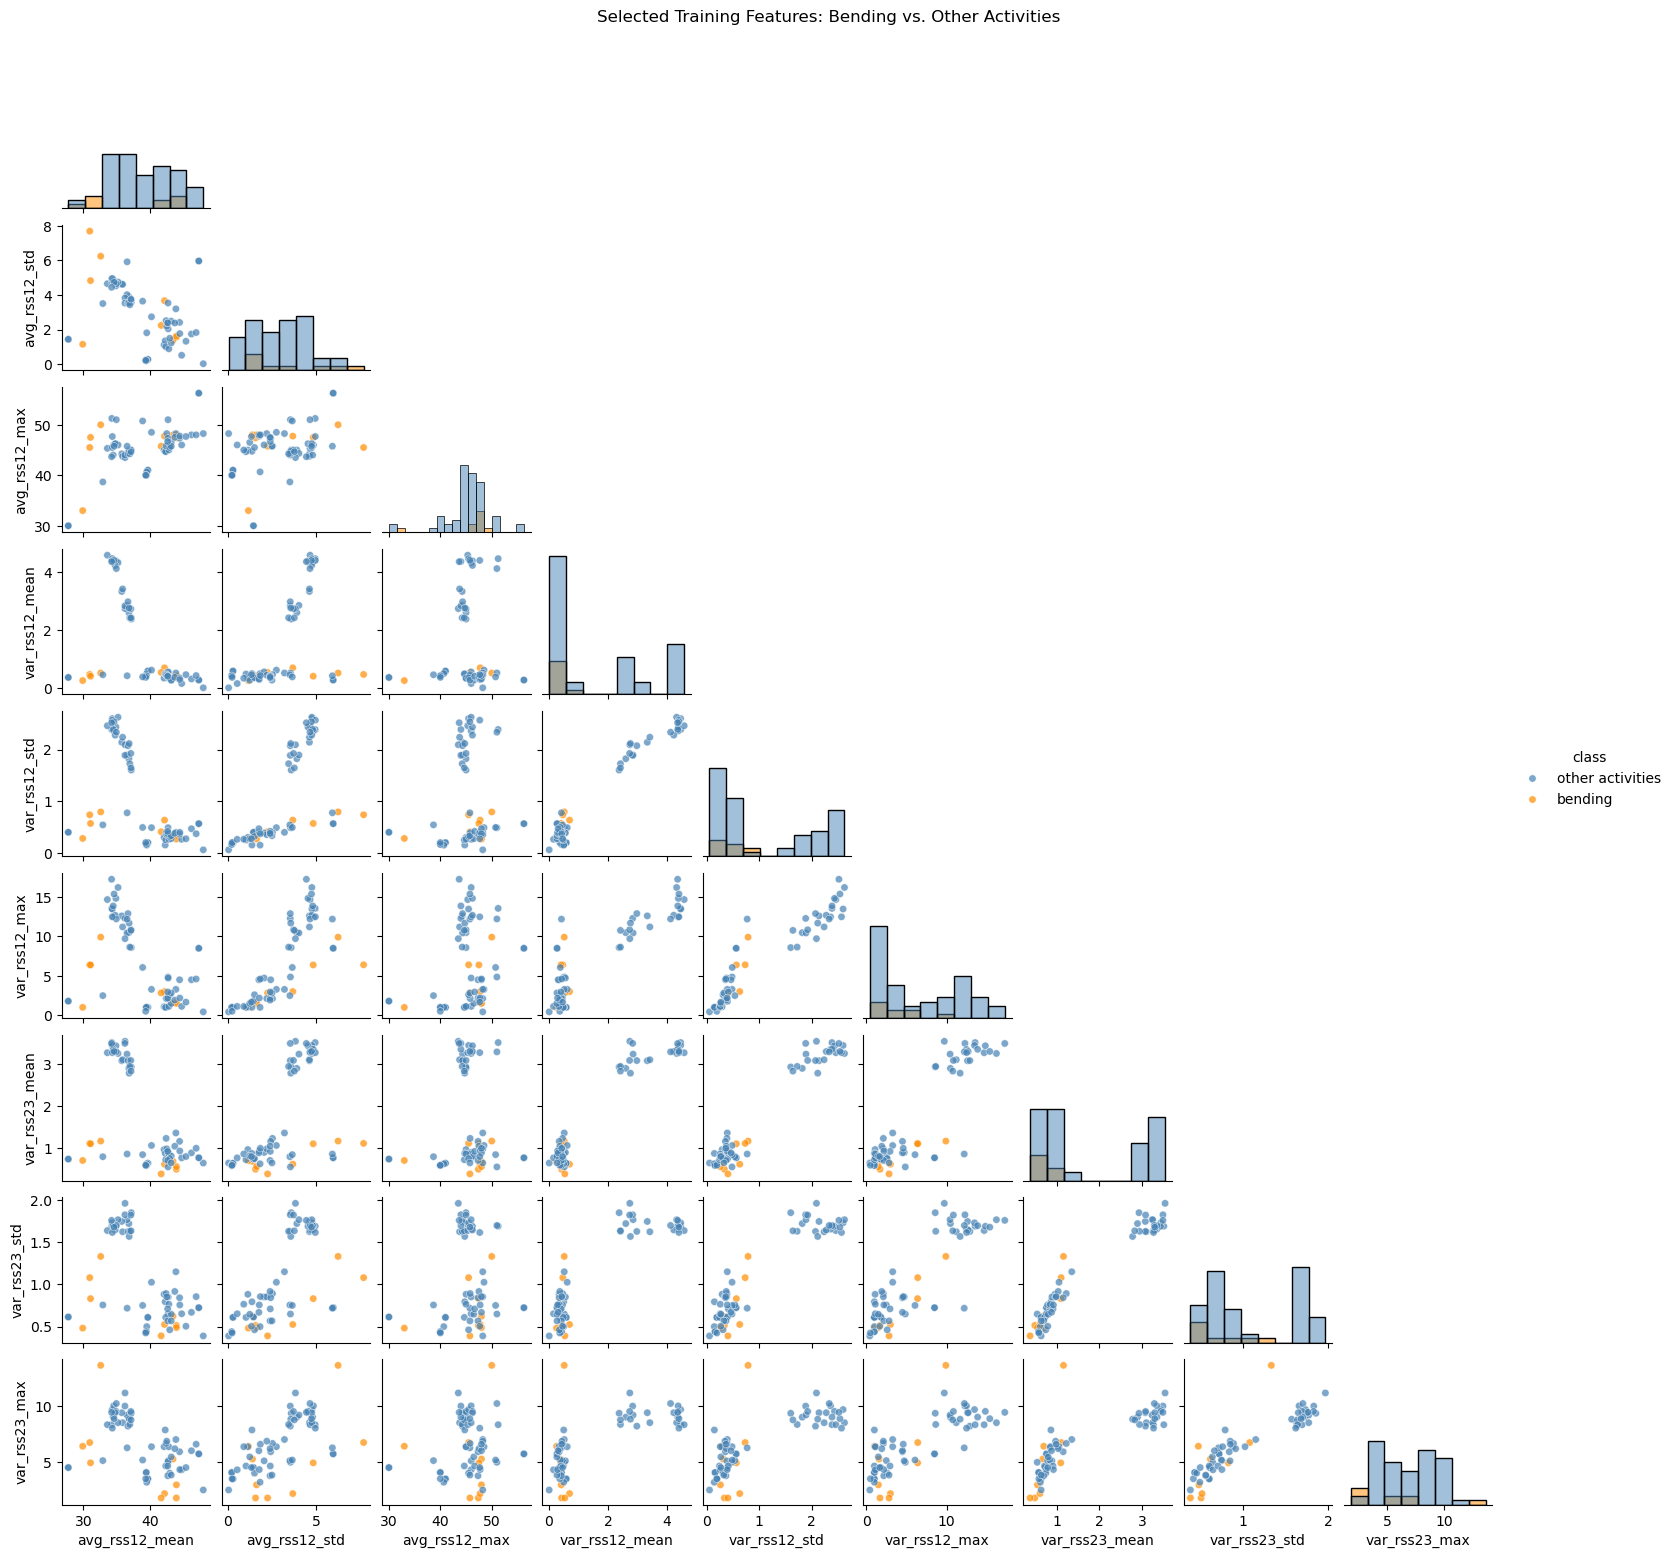

In [6]:
# Time series 1, 2, and 6 correspond to these columns in SENSOR_COLUMNS.
selected_series_numbers = [1, 2, 6]
selected_statistics = ["mean", "std", "max"]

selected_sensors = [
    SENSOR_COLUMNS[series_number - 1]
    for series_number in selected_series_numbers
]

selected_features = [
    f"{sensor}_{statistic}"
    for sensor in selected_sensors
    for statistic in selected_statistics
]

train_scatter_data = train_manifest[
    ["activity", "dataset_num"]
].merge(
    feature_table,
    on=["activity", "dataset_num"],
    how="left",
    validate="one_to_one",
)

train_scatter_data["class"] = np.where(
    train_scatter_data["activity"].isin(["bending1", "bending2"]),
    "bending",
    "other activities",
)

scatter_matrix = sns.pairplot(
    data=train_scatter_data,
    vars=selected_features,
    hue="class",
    hue_order=["other activities", "bending"],
    palette={
        "other activities": "steelblue",
        "bending": "darkorange",
    },
    corner=True,
    diag_kind="hist",
    height=1.7,
    plot_kws={"alpha": 0.7, "s": 28},
)

scatter_matrix.fig.suptitle(
    "Selected Training Features: Bending vs. Other Activities",
    y=1.02,
)

plt.show()

### 2(a)(ii) Split Each Time Series into Two Parts

In [7]:
half_feature_records = []

for row in train_manifest.itertuples(index=False):
    frame = read_activity_file(row.file_path)

    record = {
        "instance": f"{row.activity}_dataset{row.dataset_num}",
        "activity": row.activity,
        "dataset_num": row.dataset_num,
    }

    for sensor in selected_sensors:
        # If the number of observations is odd, the two parts differ by one row.
        segments = np.array_split(frame[sensor].to_numpy(), 2)

        for part_number, values in enumerate(segments, start=1):
            segment = pd.Series(values)

            segment_statistics = {
                "mean": segment.mean(),
                "std": segment.std(ddof=1),
                "max": segment.max(),
            }

            for statistic in selected_statistics:
                feature_name = f"{sensor}_part{part_number}_{statistic}"
                record[feature_name] = segment_statistics[statistic]

    half_feature_records.append(record)

half_feature_table = pd.DataFrame(half_feature_records)

HALF_FEATURE_COLUMNS = [
    f"{sensor}_part{part_number}_{statistic}"
    for sensor in selected_sensors
    for part_number in [1, 2]
    for statistic in selected_statistics
]

half_feature_table["class"] = np.where(
    half_feature_table["activity"].isin(["bending1", "bending2"]),
    "bending",
    "other activities",
)

print(f"Training data shape: {half_feature_table.shape}")
print(f"Number of selected features: {len(HALF_FEATURE_COLUMNS)}")
print(half_feature_table["class"].value_counts())

Training data shape: (69, 22)
Number of selected features: 18
class
other activities    60
bending              9
Name: count, dtype: int64


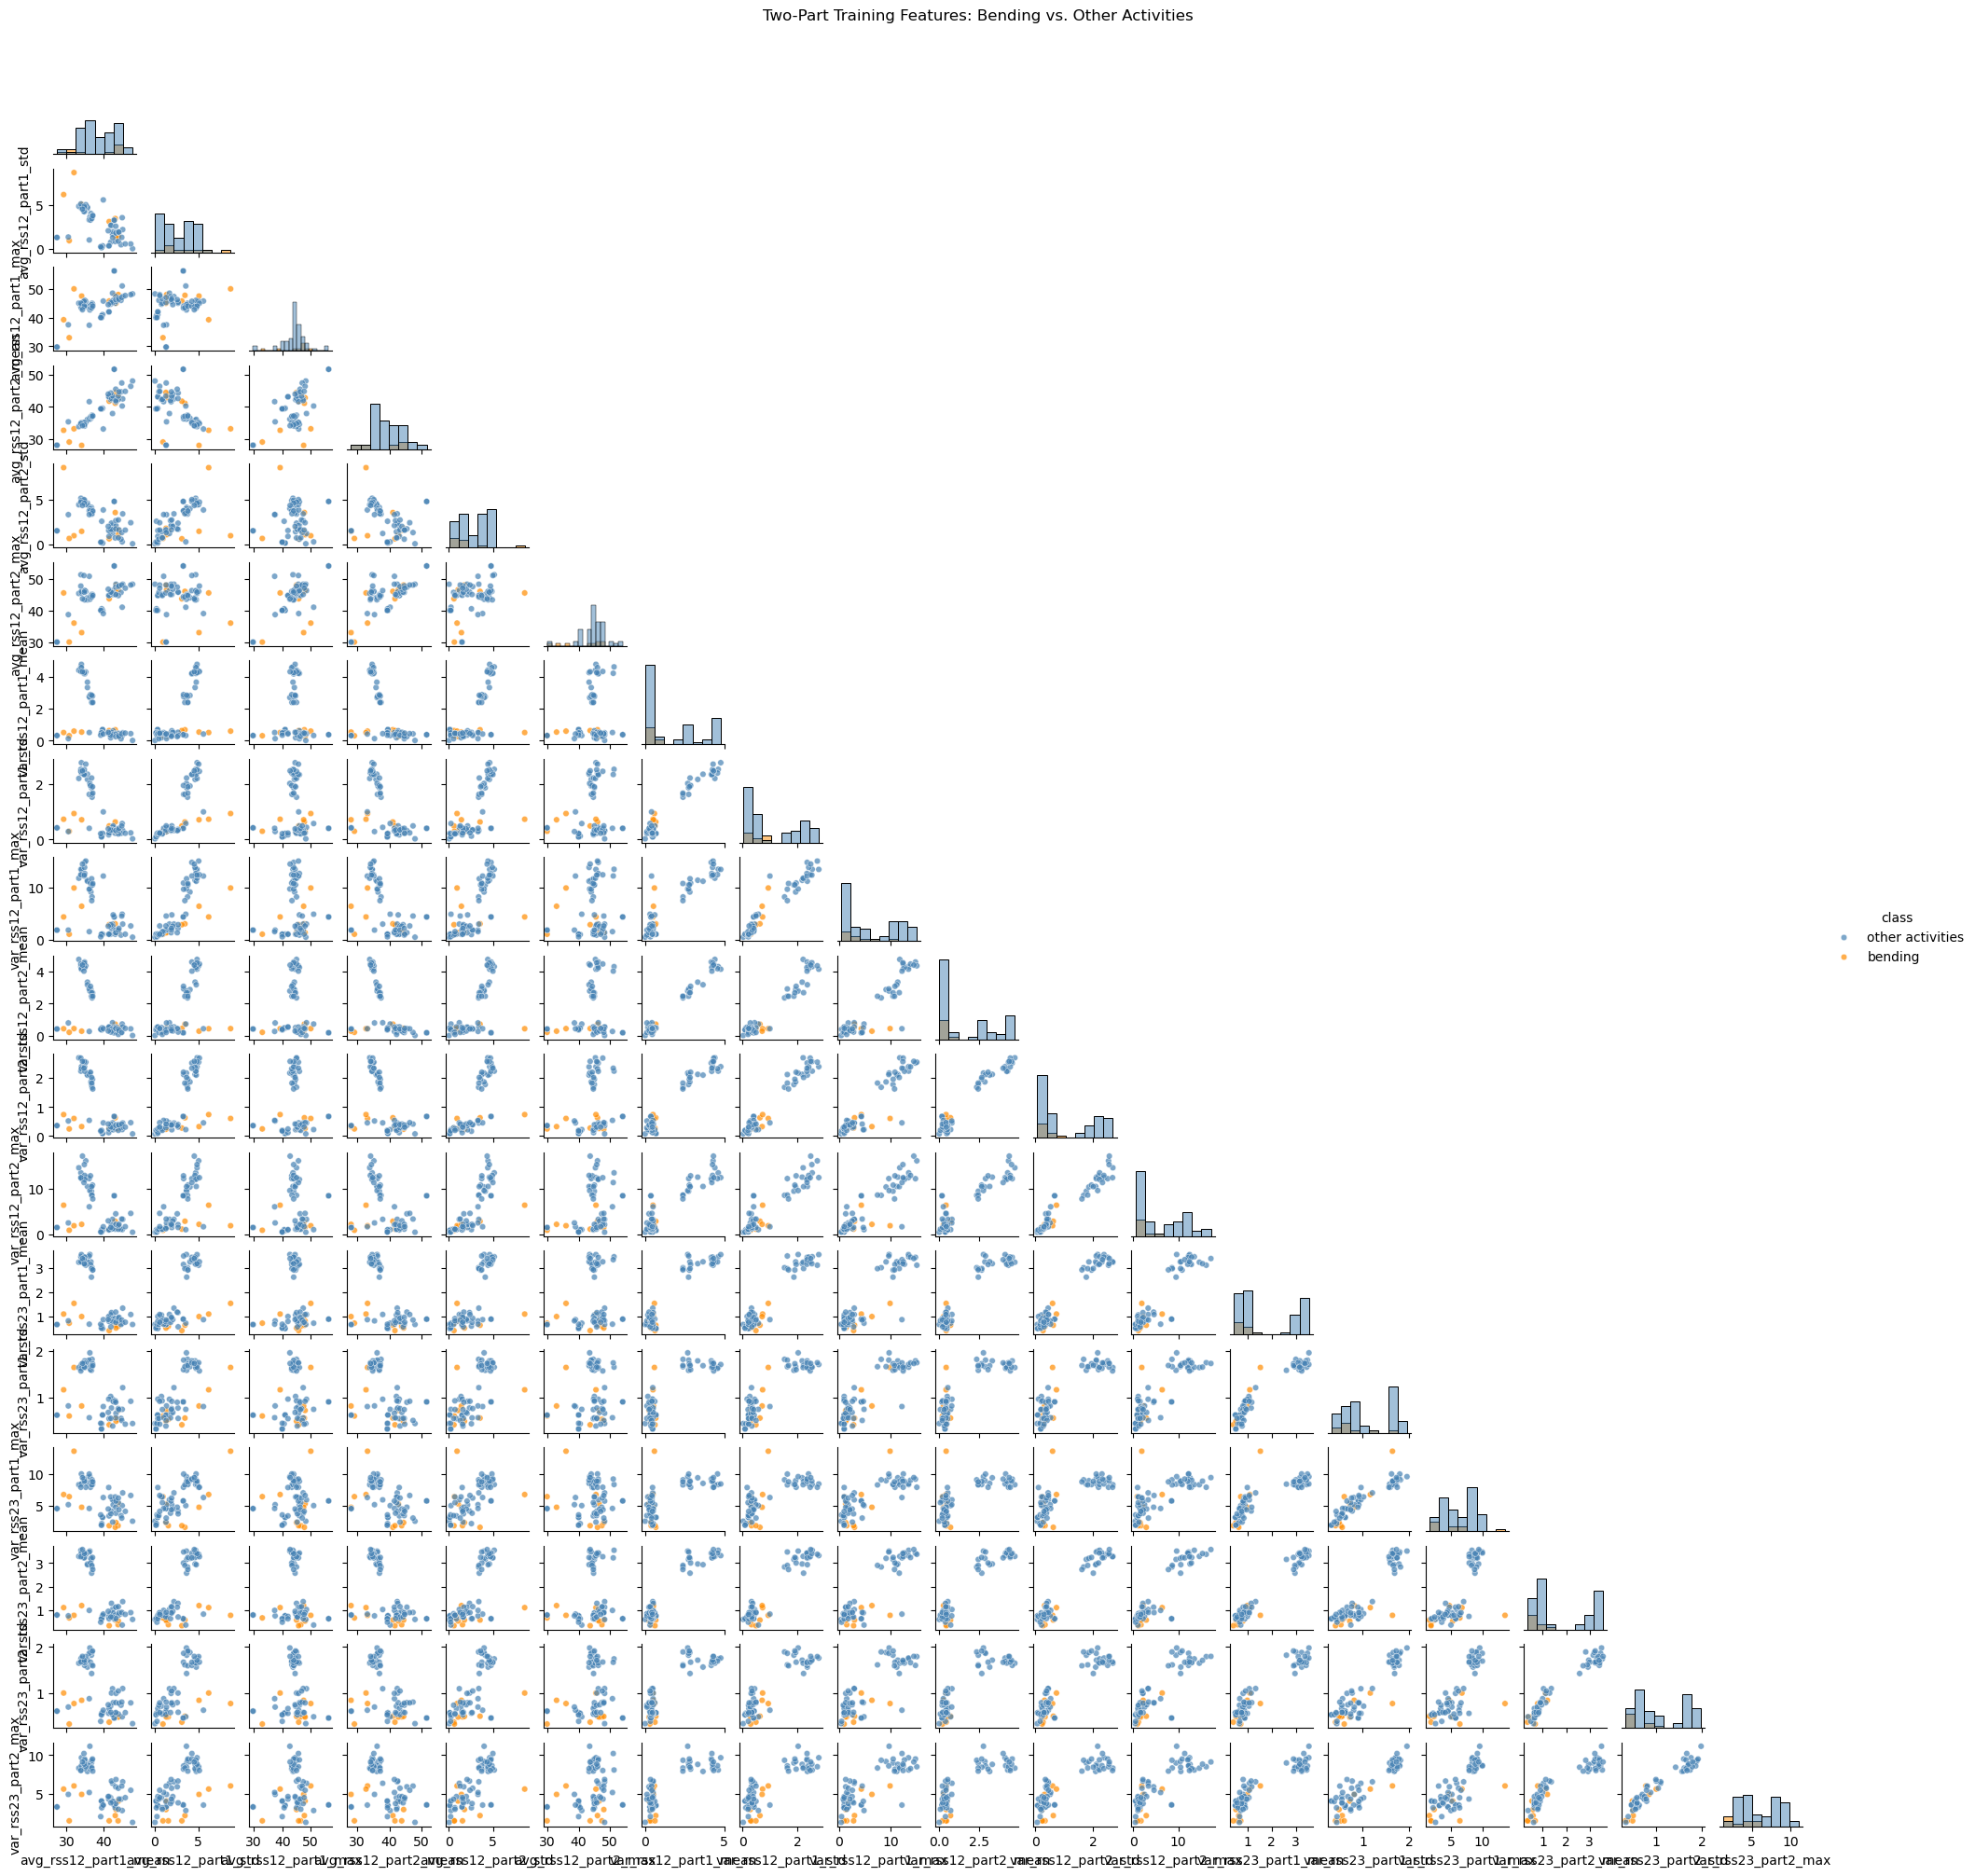

In [8]:
half_scatter_matrix = sns.pairplot(
    data=half_feature_table,
    vars=HALF_FEATURE_COLUMNS,
    hue="class",
    hue_order=["other activities", "bending"],
    palette={
        "other activities": "steelblue",
        "bending": "darkorange",
    },
    corner=True,
    diag_kind="hist",
    height=1.1,
    plot_kws={"alpha": 0.7, "s": 22},
)

half_scatter_matrix.fig.suptitle(
    "Two-Part Training Features: Bending vs. Other Activities",
    y=1.02,
)

plt.show()

### 2(a)(iii) Logistic Regression with Recursive Feature Elimination

In [9]:
def extract_segmented_features(frame, n_segments):
    features = {}

    for sensor in SENSOR_COLUMNS:
        segments = np.array_split(
            frame[sensor].to_numpy(),
            n_segments,
        )

        for segment_number, values in enumerate(segments, start=1):
            segment = pd.Series(values)

            segment_statistics = {
                "mean": segment.mean(),
                "std": segment.std(ddof=1),
                "max": segment.max(),
            }

            for statistic in selected_statistics:
                feature_name = (
                    f"{sensor}_segment{segment_number}_{statistic}"
                )
                features[feature_name] = segment_statistics[statistic]

    return features


# Read each training file once, then reuse it for every value of l.
training_instances = []

for row in train_manifest.itertuples(index=False):
    training_instances.append(
        (
            row.activity,
            row.dataset_num,
            read_activity_file(row.file_path),
        )
    )


segmented_train_tables = {}

for l in range(1, 21):
    records = []

    for activity, dataset_num, frame in training_instances:
        record = {
            "activity": activity,
            "dataset_num": dataset_num,
            "class": (
                "bending"
                if activity in ["bending1", "bending2"]
                else "other activities"
            ),
        }

        record.update(extract_segmented_features(frame, l))
        records.append(record)

    segmented_train_tables[l] = pd.DataFrame(records)

print("Training instances:", len(train_manifest))
print("Feature count when l = 1:",
      segmented_train_tables[1].shape[1] - 3)
print("Feature count when l = 20:",
      segmented_train_tables[20].shape[1] - 3)

Training instances: 69
Feature count when l = 1: 18
Feature count when l = 20: 360


In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=514,
)

# Search p from 1 to 30, limited by the number of available features.
# The upper bound keeps this initial search manageable.
P_CANDIDATES = range(1, 31)

cv_records = []

for l, table in segmented_train_tables.items():
    feature_columns = [
        column
        for column in table.columns
        if column not in ["activity", "dataset_num", "class"]
    ]

    X = table[feature_columns]
    y = table["class"]

    valid_p_values = [
        p for p in P_CANDIDATES
        if p <= len(feature_columns)
    ]

    for p in valid_p_values:
        rfe = RFE(
            estimator=LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=3000,
            ),
            n_features_to_select=p,
            step=0.1,
        )

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", rfe),
            ("logistic_regression", LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=3000,
            )),
        ])

        scores = cross_validate(
            model,
            X,
            y,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
            },
        )

        cv_records.append({
            "l": l,
            "p": p,
            "mean_cv_accuracy": scores["test_accuracy"].mean(),
            "mean_cv_balanced_accuracy":
                scores["test_balanced_accuracy"].mean(),
        })

cv_results = pd.DataFrame(cv_records)

# Select the pair with the highest mean 5-fold CV accuracy.
cv_summary = cv_results.sort_values(
    ["mean_cv_accuracy", "mean_cv_balanced_accuracy"],
    ascending=False,
).reset_index(drop=True)

best_cv_result = cv_summary.iloc[0]

display(cv_summary.head(10))
print(f"Selected l: {int(best_cv_result['l'])}")
print(f"Selected p: {int(best_cv_result['p'])}")
print(f"Mean CV accuracy: {best_cv_result['mean_cv_accuracy']:.3f}")
print(
    "Mean CV balanced accuracy: "
    f"{best_cv_result['mean_cv_balanced_accuracy']:.3f}"
)

,l,p,mean_cv_accuracy,mean_cv_balanced_accuracy
0,13,26,0.971429,0.983333
1,13,29,0.971429,0.983333
2,1,4,0.971429,0.941667
3,6,10,0.971429,0.941667
4,9,3,0.971429,0.941667
5,10,4,0.971429,0.941667
6,10,24,0.971429,0.941667
7,12,4,0.971429,0.941667
8,12,5,0.971429,0.941667
9,12,6,0.971429,0.941667


Selected l: 13
Selected p: 26
Mean CV accuracy: 0.971
Mean CV balanced accuracy: 0.983


### 2(a)(iv) The confusion matrix, the ROC and AUC 

Using the values of \(l\) and \(p\) selected by cross-validation, I fit a logistic regression model on the training set. I report the training confusion matrix, ROC curve, and AUC, along with the logistic regression coefficients and their p-values.

The training results show how well the model fits the data used to train it. Because the classes are perfectly separated on the training set, the unpenalized logistic regression estimates may be unstable. Following the assignment's recommendation, I limit the number of optimization iterations when estimating the coefficients and p-values. These estimates should therefore be interpreted with caution.

In [11]:
selected_l = int(best_cv_result["l"])
selected_p = int(best_cv_result["p"])

# Extract segmented features for each training instance
train_feature_records = []

for row in train_manifest.itertuples(index=False):
    frame = read_activity_file(row.file_path)

    feature_record = extract_segmented_features(
        frame,
        n_segments=selected_l,
    )
    feature_record["activity"] = row.activity
    train_feature_records.append(feature_record)

train_feature_table = pd.DataFrame(train_feature_records)

X_train = train_feature_table.drop(columns="activity")
y_train = train_feature_table["activity"].isin(
    {"bending1", "bending2"}
).astype(int)

In [12]:
# Scale the features, select p features with RFE, and fit logistic regression
final_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "rfe",
        RFE(
            estimator=LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=3000,
            ),
            n_features_to_select=selected_p,
            step=0.1,
        ),
    ),
    (
        "logistic",
        LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=3000,
        ),
    ),
])

final_model.fit(X_train, y_train)

Pipeline(steps=[('scale', StandardScaler()),
                ('rfe',
                 RFE(estimator=LogisticRegression(max_iter=3000, penalty=None),
                     n_features_to_select=26, step=0.1)),
                ('logistic', LogisticRegression(max_iter=3000, penalty=None))])

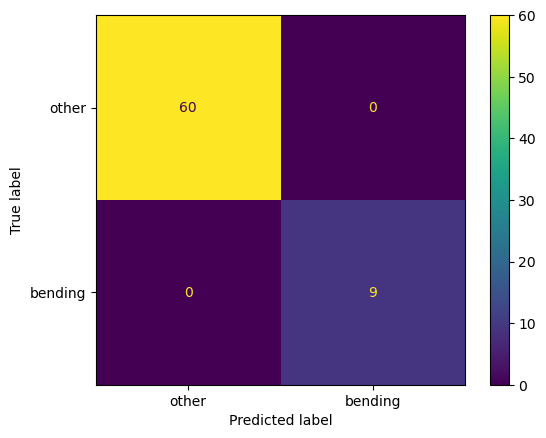

In [13]:
# Predict the training labels and display the confusion matrix
y_train_pred = final_model.predict(X_train)

cm = confusion_matrix(
    y_train,
    y_train_pred,
    labels=[0, 1],
)

display(
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["other", "bending"],
    ).plot()
)

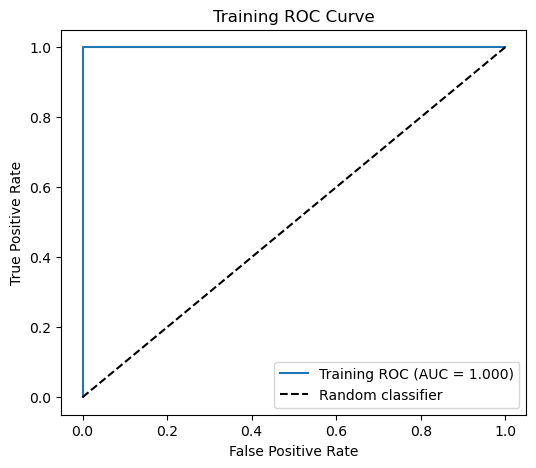

Training AUC: 1.000


In [14]:
y_train_prob = final_model.predict_proba(X_train)[:, 1]

fpr, tpr, thresholds = roc_curve(y_train, y_train_prob)
train_auc = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Training ROC (AUC = {train_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

print(f"Training AUC: {train_auc:.3f}")

In [15]:
matrix_rank = np.linalg.matrix_rank(X_for_statsmodels.to_numpy())
print(f"Matrix rank: {matrix_rank} / {X_for_statsmodels.shape[1]}")

NameError: name 'X_for_statsmodels' is not defined

In [ ]:
statsmodels_result = sm.Logit(
    y_train,
    X_for_statsmodels,
).fit(
    method="bfgs",
    maxiter=5,
    disp=False,
)

e:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [ ]:
print(statsmodels_result.mle_retvals["converged"])

False


In [ ]:
# Find the features retained by RFE
selected_mask = final_model.named_steps["rfe"].support_
selected_feature_names = X_train.columns[selected_mask]

# Transform the training data using the fitted scaler and keep selected features
X_scaled = final_model.named_steps["scale"].transform(X_train)

X_selected_scaled = pd.DataFrame(
    X_scaled[:, selected_mask],
    columns=selected_feature_names,
    index=X_train.index,
)

# Add an intercept and fit the model with a limited number of iterations
X_for_statsmodels = sm.add_constant(X_selected_scaled)
statsmodels_result = sm.Logit(
    y_train,
    X_for_statsmodels,
).fit(
    method="bfgs",
    maxiter=10,
    disp=False,
)

coefficient_table = pd.DataFrame({
    "coefficient": statsmodels_result.params,
    "p_value": statsmodels_result.pvalues,
})

display(coefficient_table)

e:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,coefficient,p_value
const,-6.519946,0.507191
avg_rss12_segment3_std,-0.980151,0.980364
avg_rss12_segment5_mean,0.890692,0.978583
avg_rss12_segment8_mean,-0.228074,0.997493
avg_rss12_segment8_max,-0.718715,0.981974
avg_rss12_segment9_mean,-0.070772,0.999528
avg_rss12_segment9_max,-1.246860,0.982211
avg_rss12_segment10_mean,-0.095184,0.999157
avg_rss13_segment3_max,-0.171139,0.994849
avg_rss13_segment6_std,-1.126299,0.946201


### 2(a)(v) Five-fold cross-validation

In [ ]:
# Extract segmented features for each test instance
test_feature_records = []

for row in test_manifest.itertuples(index=False):
    frame = read_activity_file(row.file_path)

    feature_record = extract_segmented_features(
        frame,
        n_segments=selected_l,
    )
    feature_record["activity"] = row.activity
    test_feature_records.append(feature_record)

test_feature_table = pd.DataFrame(test_feature_records)

# Match the test feature columns to the training feature columns
X_test = test_feature_table.reindex(columns=X_train.columns)

# Encode bending as 1 and all other activities as 0
y_test = test_feature_table["activity"].isin(
    {"bending1", "bending2"}
).astype(int)

# Predict the test labels and calculate test accuracy
y_test_pred = final_model.predict(X_test)
test_accuracy = np.mean(y_test_pred == y_test)

# Retrieve the cross-validation accuracy for the selected model
cv_accuracy = float(best_cv_result["mean_cv_accuracy"])

print(f"Selected l: {selected_l}")
print(f"Selected p: {selected_p}")
print(f"Mean 5-fold Cross-Validation accuracy: {cv_accuracy:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

Selected l: 13
Selected p: 26
Mean 5-fold Cross-Validation accuracy: 0.971
Test accuracy: 0.947


The selected model uses \(l=13\) segments and \(p=26\) features. Its mean five-fold cross-validation accuracy is 0.971, and its test accuracy is 0.947 (18 of 19 test instances classified correctly). The test accuracy is slightly lower but close to the cross-validation accuracy. Since the test set contains only 19 instances, one misclassification changes the accuracy noticeably.

### 2(a)(vi) Class Separability and Parameter Stability

Yes. The classes appear to be well separated in the training data. The training confusion matrix classifies all 60 `other` instances and all 9 `bending` instances correctly, and the training AUC is 1.000. The Statsmodels fit also did not converge within the selected iteration limit (`converged=False`). These results are consistent with complete or near-complete separation, which can make the unpenalized logistic regression coefficient estimates unstable. The test accuracy of 0.947 shows that perfect training performance does not guarantee perfect performance on unseen data.

### 2(a)(vii) Case-Control Adjustment

The training set contains 60 `other` instances and 9 `bending` instances, so the classes are imbalanced. I fit a weighted logistic regression model that gives the two classes equal total weight. I then adjust the model's intercept from the balanced case-control prevalence to the original training prevalence and evaluate the adjusted model on the test set.

e:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


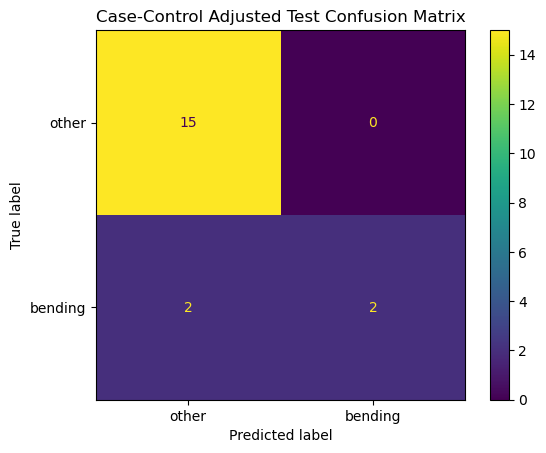

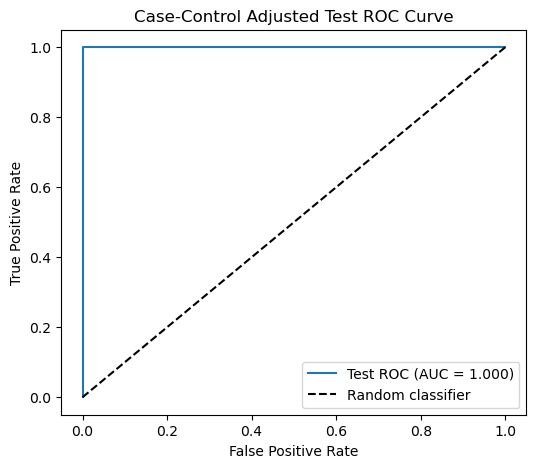

Training prevalence: 0.130
Case-control prevalence: 0.500
Intercept adjustment: -1.897
Case-control adjusted test AUC: 1.000


In [ ]:
# Get the features selected by RFE and scale the training and test features
selected_mask = final_model.named_steps["rfe"].support_
selected_feature_names = X_train.columns[selected_mask]

X_train_scaled = final_model.named_steps["scale"].transform(X_train)
X_test_scaled = final_model.named_steps["scale"].transform(X_test)

X_train_selected = pd.DataFrame(
    X_train_scaled[:, selected_mask],
    columns=selected_feature_names,
    index=X_train.index,
)

X_test_selected = pd.DataFrame(
    X_test_scaled[:, selected_mask],
    columns=selected_feature_names,
    index=X_test.index,
)

# Give each class equal total weight
n_bending = int((y_train == 1).sum())
n_other = int((y_train == 0).sum())

case_control_weights = np.where(
    y_train.to_numpy() == 1,
    1.0,
    n_bending / n_other,
)

# Fit the weighted logistic regression model
case_control_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=10,
)

case_control_model.fit(
    X_train_selected,
    y_train,
    sample_weight=case_control_weights,
)

# Adjust the intercept from the balanced sample prevalence
population_prevalence = float(y_train.mean())
case_control_prevalence = float(
    np.average(y_train, weights=case_control_weights)
)

intercept_adjustment = (
    np.log(population_prevalence / (1 - population_prevalence))
    - np.log(case_control_prevalence / (1 - case_control_prevalence))
)

# Calculate adjusted probabilities and predictions for the test set
test_log_odds_adjusted = (
    case_control_model.decision_function(X_test_selected)
    + intercept_adjustment
)

test_prob_adjusted = 1 / (
    1 + np.exp(-np.clip(test_log_odds_adjusted, -500, 500))
)

test_pred_case_control = (test_prob_adjusted >= 0.5).astype(int)

# Display the test confusion matrix
case_control_cm = confusion_matrix(
    y_test,
    test_pred_case_control,
    labels=[0, 1],
)

ConfusionMatrixDisplay(
    confusion_matrix=case_control_cm,
    display_labels=["other", "bending"],
).plot()

plt.title("Case-Control Adjusted Test Confusion Matrix")
plt.show()

# Plot the test ROC curve and calculate AUC
fpr_case_control, tpr_case_control, _ = roc_curve(
    y_test,
    test_prob_adjusted,
)

case_control_auc = roc_auc_score(y_test, test_prob_adjusted)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr_case_control,
    tpr_case_control,
    label=f"Test ROC (AUC = {case_control_auc:.3f})",
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control Adjusted Test ROC Curve")
plt.legend()
plt.show()

print(f"Training prevalence: {population_prevalence:.3f}")
print(f"Case-control prevalence: {case_control_prevalence:.3f}")
print(f"Intercept adjustment: {intercept_adjustment:.3f}")
print(f"Case-control adjusted test AUC: {case_control_auc:.3f}")

The training set has 9 `bending` and 60 `other` instances, so the class prevalence is 0.130. The case-control weighting gives the two classes equal total weight, producing a weighted prevalence of 0.500. I adjusted the intercept by -1.897 to account for the original training prevalence.

On the test set, the adjusted model correctly classified all 15 `other` instances and 2 of the 4 `bending` instances, for an accuracy of 0.895. The test AUC is 1.000, meaning that all `bending` cases received higher scores than all `other` cases. The AUC remains perfect even though two `bending` cases fall below the adjusted 0.5 classification threshold.

### 2(b)(i)

In [ ]:
# Cache the training time series and create the binary training labels
train_frames_l1 = [
    read_activity_file(row.file_path)
    for row in train_manifest.itertuples(index=False)
]

y_train_l1 = train_manifest["activity"].isin(
    {"bending1", "bending2"}
).astype(int).reset_index(drop=True)

# Define the candidate regularization strengths
C_CANDIDATES = np.logspace(-3, 2, 6)

# Use stratified five-fold cross-validation
cv_l1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=514,
)

l1_cv_records = []

# Evaluate each number of segments and each C value
for n_segments in range(1, 21):
    X_l1 = pd.DataFrame([
        extract_segmented_features(frame, n_segments=n_segments)
        for frame in train_frames_l1
    ])

    for C_value in C_CANDIDATES:
        l1_model = Pipeline([
            ("scale", StandardScaler()),
            (
                "logistic",
                LogisticRegression(
                    penalty="l1",
                    solver="saga",
                    C=float(C_value),
                    max_iter=1000,
                    tol=1e-3,
                ),
            ),
        ])

        cv_scores = cross_validate(
            l1_model,
            X_l1,
            y_train_l1,
            cv=cv_l1,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
            },
        )

        l1_cv_records.append({
            "l": n_segments,
            "C": float(C_value),
            "mean_cv_accuracy": cv_scores["test_accuracy"].mean(),
            "mean_cv_balanced_accuracy": (
                cv_scores["test_balanced_accuracy"].mean()
            ),
        })

# Rank by accuracy, then balanced accuracy; prefer stronger regularization
l1_cv_results = (
    pd.DataFrame(l1_cv_records)
    .sort_values(
        ["mean_cv_accuracy", "mean_cv_balanced_accuracy", "C"],
        ascending=[False, False, True],
    )
    .reset_index(drop=True)
)

display(l1_cv_results.head(10))

# Save the best parameter pair for the next subsection
best_l1_cv_result = l1_cv_results.iloc[0]
selected_l_l1 = int(best_l1_cv_result["l"])
selected_C_l1 = float(best_l1_cv_result["C"])

print(f"Selected l: {selected_l_l1}")
print(f"Selected C: {selected_C_l1:.6g}")
print(f"Mean Cross-Validation accuracy: {best_l1_cv_result['mean_cv_accuracy']:.3f}")
print(
    "Mean Cross-Validation balanced accuracy: "
    f"{best_l1_cv_result['mean_cv_balanced_accuracy']:.3f}"
)

,l,C,mean_cv_accuracy,mean_cv_balanced_accuracy
0,1,10.0,0.971429,0.941667
1,1,100.0,0.971429,0.941667
2,6,10.0,0.957143,0.933333
3,1,1.0,0.957143,0.891667
4,3,1.0,0.957143,0.850000
5,8,1.0,0.957143,0.850000
6,9,1.0,0.957143,0.850000
7,13,10.0,0.942857,0.925000
8,9,100.0,0.942857,0.925000
9,6,100.0,0.942857,0.883333


Selected l: 1
Selected C: 10
Mean Cross-Validation accuracy: 0.971
Mean Cross-Validation balanced accuracy: 0.942


### 2(b)(ii)

The L1-penalized logistic regression achieved a mean 5-fold cross-validation accuracy of 0.971 and a mean balanced accuracy of 0.942.

P-value-based variable selection would use coefficient p-values to select features and then refit the model. However, the Statsmodels logistic regression fit in this analysis did not converge. In addition, the reported p-values were calculated for features already selected by RFE; they were not used to perform an independent p-value-based feature selection and refitting procedure. Therefore, I do not have a valid cross-validation score for a p-value-selected model and cannot determine which method has better predictive performance from these results. The RFE results in Part 2(a)(iii) are for a different feature-selection procedure and should not be treated as p-value-based results.

L1 regularization is easier to implement in this analysis because feature selection is incorporated into model fitting: some coefficients are shrunk to zero. P-value-based selection requires fitting the model, evaluating the p-values, selecting features, and refitting the model. The non-convergence encountered here also makes the p-value-based approach more difficult to apply reliably.

### 2(c)(i)

In [ ]:
def build_multiclass_features(data_manifest, n_segments):
    feature_records = []

    for row in data_manifest.itertuples(index=False):
        frame = read_activity_file(row.file_path)

        feature_record = extract_segmented_features(
            frame,
            n_segments=n_segments,
        )
        feature_record["activity"] = row.activity
        feature_records.append(feature_record)

    return pd.DataFrame(feature_records)


MULTICLASS_C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]
MULTICLASS_L_VALUES = range(1, 21)

multiclass_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=552,
)

multiclass_cv_results = []

for l_value in MULTICLASS_L_VALUES:
    train_features_l = build_multiclass_features(
        train_manifest,
        n_segments=l_value,
    )

    X_l = train_features_l.drop(columns="activity")
    y_l = train_features_l["activity"]

    for c_value in MULTICLASS_C_VALUES:
        model = Pipeline([
            ("scale", StandardScaler()),
            (
                "logistic",
                LogisticRegression(
                    penalty="l1",
                    solver="saga",
                    C=c_value,
                    max_iter=10000,
                    tol=1e-3,
                    random_state=552,
                ),
            ),
        ])

        scores = cross_validate(
            model,
            X_l,
            y_l,
            cv=multiclass_cv,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
            },
            n_jobs=-1,
            error_score="raise",
        )

        multiclass_cv_results.append({
            "l": l_value,
            "C": c_value,
            "mean_cv_accuracy": scores["test_accuracy"].mean(),
            "mean_cv_balanced_accuracy": scores[
                "test_balanced_accuracy"
            ].mean(),
        })

multiclass_cv_table = pd.DataFrame(multiclass_cv_results).sort_values(
    ["mean_cv_accuracy", "mean_cv_balanced_accuracy", "C", "l"],
    ascending=[False, False, True, True],
).reset_index(drop=True)

display(multiclass_cv_table.head(10))

best_multiclass_result = multiclass_cv_table.iloc[0]
selected_l_multiclass = int(best_multiclass_result["l"])
selected_C_multiclass = float(best_multiclass_result["C"])

print(f"Selected l: {selected_l_multiclass}")
print(f"Selected C: {selected_C_multiclass:g}")
print(
    "Mean4-fold CV accuracy: "
    f"{best_multiclass_result['mean_cv_accuracy']:.3f}"
)
print(
    "Mean 4-fold CV balanced accuracy: "
    f"{best_multiclass_result['mean_cv_balanced_accuracy']:.3f}"
)

,l,C,mean_cv_accuracy,mean_cv_balanced_accuracy
0,1,1.0,0.928105,0.892857
1,1,10.0,0.898693,0.892857
2,1,100.0,0.883987,0.857143
3,3,100.0,0.869281,0.821429
4,5,100.0,0.869281,0.773810
5,3,1.0,0.854575,0.809524
6,5,10.0,0.854575,0.761905
7,15,100.0,0.854575,0.761905
8,12,100.0,0.840686,0.750000
9,3,10.0,0.839869,0.773810


Selected l: 1
Selected C: 1
Mean 5-fold CV accuracy: 0.928
Mean 5-fold CV balanced accuracy: 0.893


Test accuracy: 0.947
Test error: 0.053


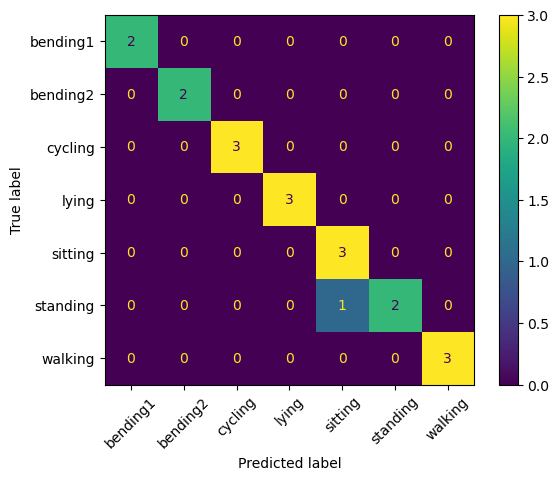

In [18]:
train_multiclass_features = build_multiclass_features(
    train_manifest,
    n_segments=selected_l_multiclass,
)
test_multiclass_features = build_multiclass_features(
    test_manifest,
    n_segments=selected_l_multiclass,
)

X_train_multiclass = train_multiclass_features.drop(columns="activity")
y_train_multiclass = train_multiclass_features["activity"]

X_test_multiclass = test_multiclass_features.drop(columns="activity")
y_test_multiclass = test_multiclass_features["activity"]

final_multiclass_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "logistic",
        LogisticRegression(
            penalty="l1",
            solver="saga",
            C=selected_C_multiclass,
            max_iter=10000,
            tol=1e-3,
            random_state=552,
        ),
    ),
])

final_multiclass_model.fit(X_train_multiclass, y_train_multiclass)

y_test_multiclass_pred = final_multiclass_model.predict(
    X_test_multiclass
)
y_test_multiclass_prob = final_multiclass_model.predict_proba(
    X_test_multiclass
)

test_accuracy_multiclass = np.mean(
    y_test_multiclass_pred == y_test_multiclass
)
test_error_multiclass = 1 - test_accuracy_multiclass

print(f"Test accuracy: {test_accuracy_multiclass:.3f}")
print(f"Test error: {test_error_multiclass:.3f}")

activity_labels = final_multiclass_model.classes_

cm_multiclass = confusion_matrix(
    y_test_multiclass,
    y_test_multiclass_pred,
    labels=activity_labels,
)

display(
    ConfusionMatrixDisplay(
        confusion_matrix=cm_multiclass,
        display_labels=activity_labels,
    ).plot(xticks_rotation=45)
)

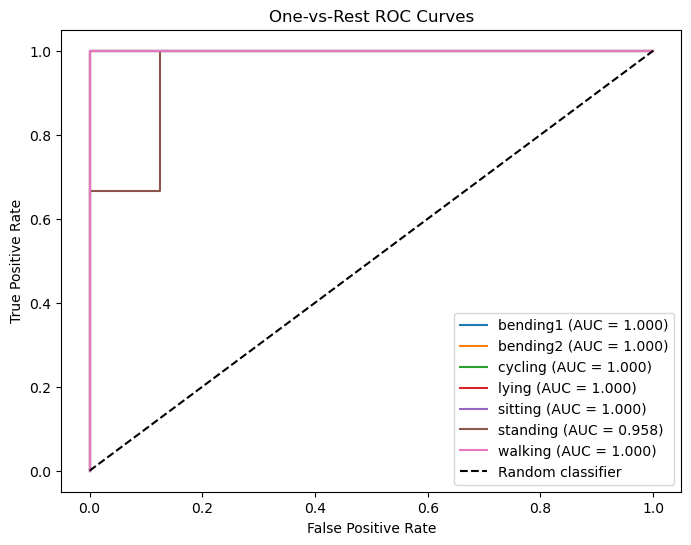

Macro-average one-vs-rest AUC: 0.994


In [19]:
y_test_multiclass_binary = (
    y_test_multiclass.to_numpy()[:, None] == activity_labels[None, :]
).astype(int)

plt.figure(figsize=(8, 6))

class_auc_values = []

for class_index, activity in enumerate(activity_labels):
    fpr, tpr, _ = roc_curve(
        y_test_multiclass_binary[:, class_index],
        y_test_multiclass_prob[:, class_index],
    )
    class_auc = roc_auc_score(
        y_test_multiclass_binary[:, class_index],
        y_test_multiclass_prob[:, class_index],
    )
    class_auc_values.append(class_auc)

    plt.plot(
        fpr,
        tpr,
        label=f"{activity} (AUC = {class_auc:.3f})",
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend(loc="lower right")
plt.show()

print(f"Macro-average one-vs-rest AUC: {np.mean(class_auc_values):.3f}")

### 2(c)(ii) Gaussian and Multinomial Naive Bayes

In [23]:
NB_L_VALUES = range(1, 21)

nb_classifiers = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(),
}

nb_cv_results = []

for l_value in NB_L_VALUES:
    train_features_l = build_multiclass_features(
        train_manifest,
        n_segments=l_value,
    )

    X_l = train_features_l.drop(columns="activity")
    y_l = train_features_l["activity"]

    if (X_l < 0).any().any():
        raise ValueError(
            "MultinomialNB requires non-negative feature values."
        )

    for model_name, classifier in nb_classifiers.items():
        scores = cross_validate(
            classifier,
            X_l,
            y_l,
            cv=multiclass_cv,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
            },
            n_jobs=-1,
            error_score="raise",
        )

        nb_cv_results.append({
            "model": model_name,
            "l": l_value,
            "mean_cv_accuracy": scores["test_accuracy"].mean(),
            "mean_cv_balanced_accuracy": scores[
                "test_balanced_accuracy"
            ].mean(),
        })

nb_cv_table = pd.DataFrame(nb_cv_results).sort_values(
    ["model", "mean_cv_accuracy", "mean_cv_balanced_accuracy", "l"],
    ascending=[True, False, False, True],
).reset_index(drop=True)

display(nb_cv_table)

best_nb_results = (
    nb_cv_table
    .groupby("model", sort=False)
    .head(1)
    .reset_index(drop=True)
)

display(best_nb_results)

,model,l,mean_cv_accuracy,mean_cv_balanced_accuracy
0,GaussianNB,1,0.898693,0.892857
1,GaussianNB,4,0.870098,0.761905
2,GaussianNB,2,0.855392,0.750000
3,GaussianNB,3,0.827614,0.750000
4,GaussianNB,5,0.825980,0.750000
5,GaussianNB,7,0.825980,0.726190
6,GaussianNB,6,0.811275,0.714286
7,GaussianNB,12,0.811275,0.714286
8,GaussianNB,19,0.797386,0.702381
9,GaussianNB,10,0.796569,0.702381


,model,l,mean_cv_accuracy,mean_cv_balanced_accuracy
0,GaussianNB,1,0.898693,0.892857
1,MultinomialNB,3,0.897876,0.869048



GaussianNB
Selected l: 1
Test accuracy: 0.895
Test error: 0.105
Macro one-vs-rest AUC: 0.997


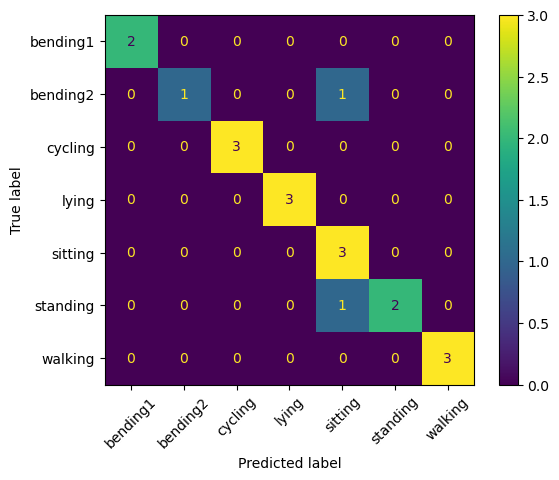

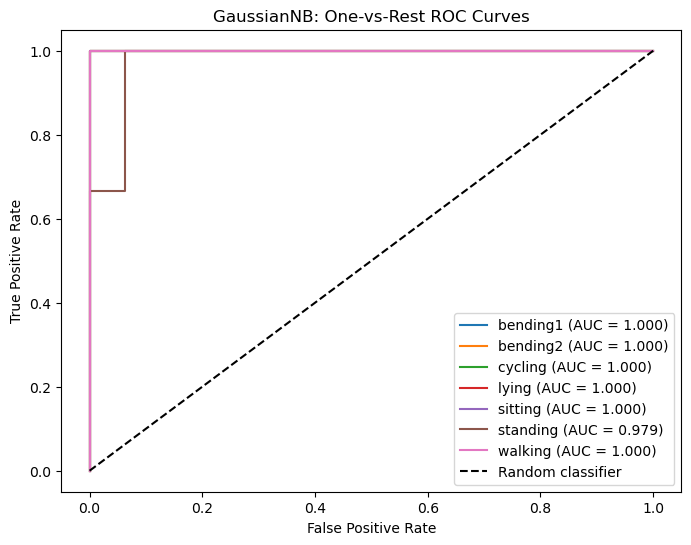


MultinomialNB
Selected l: 3
Test accuracy: 0.789
Test error: 0.211
Macro one-vs-rest AUC: 0.973


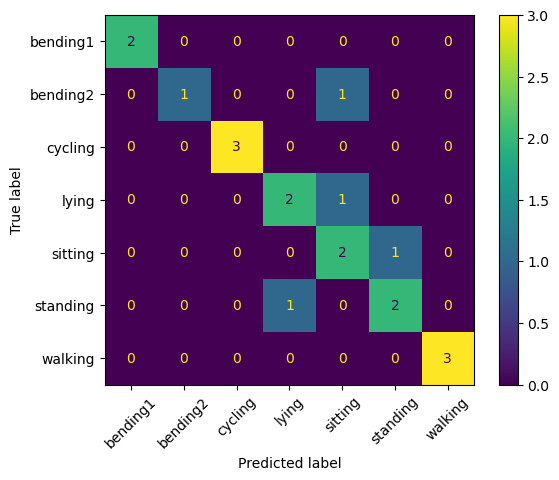

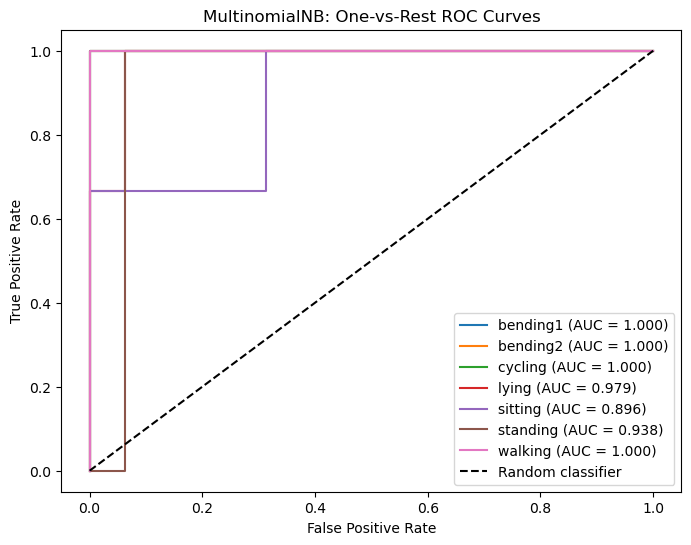

,model,selected_l,test_accuracy,test_error,macro_ovr_auc
0,GaussianNB,1,0.894737,0.105263,0.997024
1,MultinomialNB,3,0.789474,0.210526,0.973214


In [24]:
nb_test_results = []
nb_fitted_models = {}

for row in best_nb_results.itertuples(index=False):
    model_name = row.model
    selected_l_nb = int(row.l)

    train_features_nb = build_multiclass_features(
        train_manifest,
        n_segments=selected_l_nb,
    )
    test_features_nb = build_multiclass_features(
        test_manifest,
        n_segments=selected_l_nb,
    )

    X_train_nb = train_features_nb.drop(columns="activity")
    y_train_nb = train_features_nb["activity"]

    X_test_nb = test_features_nb.drop(columns="activity")
    y_test_nb = test_features_nb["activity"]

    classifier = nb_classifiers[model_name]
    classifier.fit(X_train_nb, y_train_nb)

    y_pred_nb = classifier.predict(X_test_nb)
    y_prob_nb = classifier.predict_proba(X_test_nb)

    test_accuracy_nb = np.mean(y_pred_nb == y_test_nb)
    test_error_nb = 1 - test_accuracy_nb

    labels_nb = classifier.classes_
    cm_nb = confusion_matrix(
        y_test_nb,
        y_pred_nb,
        labels=labels_nb,
    )

    y_test_binary_nb = (
        y_test_nb.to_numpy()[:, None] == labels_nb[None, :]
    ).astype(int)

    class_auc_nb = []

    for class_index in range(len(labels_nb)):
        class_auc_nb.append(
            roc_auc_score(
                y_test_binary_nb[:, class_index],
                y_prob_nb[:, class_index],
            )
        )

    macro_auc_nb = np.mean(class_auc_nb)

    nb_test_results.append({
        "model": model_name,
        "selected_l": selected_l_nb,
        "test_accuracy": test_accuracy_nb,
        "test_error": test_error_nb,
        "macro_ovr_auc": macro_auc_nb,
    })

    nb_fitted_models[model_name] = {
        "model": classifier,
        "labels": labels_nb,
        "confusion_matrix": cm_nb,
        "y_test_binary": y_test_binary_nb,
        "y_test_probability": y_prob_nb,
        "class_auc": class_auc_nb,
    }

    print(f"\n{model_name}")
    print(f"Selected l: {selected_l_nb}")
    print(f"Test accuracy: {test_accuracy_nb:.3f}")
    print(f"Test error: {test_error_nb:.3f}")
    print(f"Macro one-vs-rest AUC: {macro_auc_nb:.3f}")

    display(
        ConfusionMatrixDisplay(
            confusion_matrix=cm_nb,
            display_labels=labels_nb,
        ).plot(xticks_rotation=45)
    )

    plt.figure(figsize=(8, 6))

    for class_index, activity in enumerate(labels_nb):
        fpr, tpr, _ = roc_curve(
            y_test_binary_nb[:, class_index],
            y_prob_nb[:, class_index],
        )
        plt.plot(
            fpr,
            tpr,
            label=(
                f"{activity} "
                f"(AUC = {class_auc_nb[class_index]:.3f})"
            ),
        )

    plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name}: One-vs-Rest ROC Curves")
    plt.legend(loc="lower right")
    plt.show()

nb_test_comparison = pd.DataFrame(nb_test_results)
display(nb_test_comparison)

### 2(c)(ii)

Gaussian Naive Bayes selected \(l=1\), with a mean cross-validation accuracy of 0.899 and a mean balanced accuracy of 0.893. On the test set, it correctly classified 17 of 19 instances, giving a test accuracy of 0.895 and a test error of 0.105. Its macro-average one-vs-rest AUC was 0.997. The two misclassified instances were one bending2 instance and one standing instance, both predicted as sitting.

Multinomial Naive Bayes selected \(l=3\), with a mean cross-validation accuracy of 0.898 and a mean balanced accuracy of 0.869. Its test accuracy was 0.789, its test error was 0.211, and its macro-average one-vs-rest AUC was 0.973. It correctly classified 15 of 19 test instances.

Gaussian Naive Bayes performed better than Multinomial Naive Bayes on the test accuracy, test error, and macro-average one-vs-rest AUC.




### 2(c)(iii)
Among the three models, the L1-penalized multinomial logistic regression had the highest test accuracy (0.947) and the lowest test error (0.053). Gaussian Naive Bayes had a slightly higher macro-average one-vs-rest AUC (0.997) than the L1 logistic regression model (0.994), while Multinomial Naive Bayes had the lowest test accuracy (0.789).

Based on test accuracy and error, the L1-penalized multinomial logistic regression performed best for assigning activity labels. Gaussian Naive Bayes had the strongest overall one-vs-rest AUC, so it ranked class probabilities slightly better by this metric. The test set contains only 19 instances, so these differences should be interpreted with caution.

## 3. ISLR 4.8.3

For class \(k\), assume that $(X \mid Y=k \sim N(\mu_k,\sigma_k^2))$, with prior probability $(pi_k)$. The Bayes classifier assigns $(x)$ to the class with the largest posterior probability. Since the posterior probability is proportional to $(pi_k f_k(x))$, we can compare classes using the log score

$
\delta_k(x)
= \log(\pi_k f_k(x))
= \log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\frac{1}{2}\log(2\pi).
$

The last term is the same for every class, so it can be ignored when comparing classes. Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k x}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
+\log(\pi_k)-\log(\sigma_k).
$$

This score contains an $(x^2)$ term. When the class variances differ, the coefficient of $(x^2)$ generally differs across classes and does not cancel when their scores are compared. Therefore, the decision boundary is generally quadratic in $(x)$, rather than linear. If all classes have the same variance, the $(x^2)$ terms cancel, producing a linear decision boundary, as in LDA.

## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ denote that a company issues a dividend. The prior probabilities are $P(Y=\text{Yes})=0.8$ and $P(Y=\text{No})=0.2$. The class-conditional means are $\mu_{\text{Yes}}=10$ and $\mu_{\text{No}}=0$, and both classes have variance $\sigma^2=36$.

By Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{f_{\text{Yes}}(4)P(Y=\text{Yes})}
{f_{\text{Yes}}(4)P(Y=\text{Yes})+
 f_{\text{No}}(4)P(Y=\text{No})}.
$$

Because the two classes have the same variance, the common normalizing constant in their normal densities cancels. Therefore,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8e^{-(4-10)^2/(2\cdot36)}}
{0.8e^{-(4-10)^2/(2\cdot36)}
 +0.2e^{-(4-0)^2/(2\cdot36)}}
\approx 0.752.
$$

Thus, the estimated probability that the company issues a dividend is approximately $75.2\%$.